# 10h → 2h multi-group modelling — resource-aware workflow

A lightweight companion to the existing `modeling_10h2h_*` notebooks. It preserves the important evaluation design—unseen sources and a held-out 2h capture—while avoiding duplicate dataframes, leakage-prone shuffled splits, multiple model families, and learning-curve/permutation-importance runs during iteration.

Use this notebook to select feature sets and a reasonable data cap. Run the original full workflow only once for final, thesis-reportable results.

In [1]:
from pathlib import Path
import gc
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt

# Select one of the four experiments.  Paths are relative to code/modeling/.
EXPERIMENT = 'sa54_same'  # sa54_same, sa54_diff, ip12_same, ip12_diff
CONFIGS = {
    'sa54_same': {
        'folder': '../../data/2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances',
        'eval': '2Groups_3Devices_2h_Uni_SamsungA54BudsFEAirtags_SameDistances_labeled.csv',
    },
    'sa54_diff': {
        'folder': '../../data/2Groups_3Devices_10h_apartment',
        'eval': '2Groups_3Devices_2h_uni_labeled.csv',
    },
    'ip12_same': {
        'folder': '../../data/2Groups_3Devices_10h_Seewis_IphoneAirpodsSamsungTag_SameDistances',
        'eval': '2Groups_3Devices_2h_Uni_IphoneAirpodsSamsungTag_SameDistances_labeled.csv',
    },
    'ip12_diff': {
        'folder': '../../data/2Groups_3Devices_10h_Seewis_IphoneAirpodsSamsungTag_DiffDistances',
        'eval': '2Groups_3Devices_2h_Uni_IphoneAirpodsSamsungTag_DiffDistances_labeled.csv',
    },
}

# Start at 100k per class (at most 300k rows for 0/G1/G2).
# Use None only for the final full-data run.
MAX_TRAIN_PACKETS_PER_CLASS = 100_000
MAX_EVAL_PACKETS_PER_CLASS = 100_000
RANDOM_STATE = 1
WINDOW_SECONDS = 0.5

cfg = CONFIGS[EXPERIMENT]
base = Path(cfg['folder'])
# Folder names are not perfectly uniform, so discover the five training blocks instead.
train_files = sorted(base.glob('*Hours*To*_labeled.csv'))
eval_file = base / cfg['eval']
print(f'Experiment: {EXPERIMENT}; {len(train_files)} training blocks; evaluation: {eval_file.name}')


Experiment: sa54_same; 5 training blocks; evaluation: 2Groups_3Devices_2h_Uni_SamsungA54BudsFEAirtags_SameDistances_labeled.csv


In [2]:
def add_compact_features(df: pd.DataFrame, window_seconds: float = WINDOW_SECONDS) -> pd.DataFrame:
    """Build compact numeric features without retaining raw payload columns afterwards."""
    df = df.copy()
    df['time'] = pd.to_numeric(df['time'], errors='coerce').fillna(0).astype('float32')
    df['source'] = df['source'].astype('category')

    for column in ('info', 'channel'):
        if column in df:
            encoded = pd.get_dummies(df[column], prefix='is', dtype=np.uint8)
            df = pd.concat([df.drop(columns=column), encoded], axis=1)

    # Presence/length fields are deliberately device-agnostic; raw payload strings are discarded.
    for column in ('company_id', 'uuid16', 'uuid128', 'data', 'ad_type', 'service_data'):
        if column in df:
            df[f'has_{column}'] = df[column].notna().astype(np.uint8)
            if column in ('data', 'ad_type', 'service_data'):
                df[f'{column}_length'] = df[column].fillna('').astype(str).str.len().astype('int16')

    # Source-local cadence: source is kept only for grouped splitting, never supplied to the model.
    df = df.sort_values(['source', 'time'])
    iat = df.groupby('source', observed=True)['time'].diff()
    df['iat'] = iat.fillna(0).astype('float32')
    source_iat = df.groupby('source', observed=True)['iat'].agg(['median', 'mean', 'std']).fillna(0)
    source_iat.columns = ['iat_median', 'iat_mean', 'iat_std']
    df = df.join(source_iat, on='source')

    # Capture-local co-activity; no group labels or device labels are involved.
    bins = np.floor(df['time'] / window_seconds).astype('int64')
    df['_time_bin'] = bins
    bin_stats = df.groupby('_time_bin', observed=True).agg(
        bin_total_packets=('source', 'size'), bin_distinct_sources=('source', 'nunique')
    )
    df = df.join(bin_stats, on='_time_bin')
    df['coactive_packets'] = (df['bin_total_packets'] - 1).astype('int16')
    df['coactive_sources'] = (df['bin_distinct_sources'] - 1).astype('int16')
    df['coactive_density'] = (df['coactive_packets'] / df['bin_total_packets'].clip(lower=1)).astype('float32')

    keep = [
        'source', 'time', 'group_label_multi', 'group_label', 'group_id',
        'iat', 'iat_median', 'iat_mean', 'iat_std', 'bin_total_packets',
        'bin_distinct_sources', 'coactive_packets', 'coactive_sources', 'coactive_density',
    ]
    keep += [c for c in df.columns if c.startswith('is_') or c.startswith('has_') or c.endswith('_length')]
    keep = [c for c in keep if c in df.columns]
    return df[keep].copy()

def cap_per_class(df: pd.DataFrame, label_col: str, max_rows=None) -> pd.DataFrame:
    if max_rows is None:
        return df
    return (df.groupby(label_col, group_keys=False, observed=True)
              .apply(lambda group: group.sample(n=min(len(group), max_rows), random_state=RANDOM_STATE))
              .reset_index(drop=True))


In [3]:
# Process one file at a time, retaining only its compact numeric representation.
train_parts = []
for path in train_files:
    raw = pd.read_csv(path, low_memory=False)
    compact = add_compact_features(raw)
    train_parts.append(compact)
    print(f'{path.name}: raw={len(raw):,}, compact={len(compact):,}')
    del raw, compact
    gc.collect()

train_df = pd.concat(train_parts, ignore_index=True)
del train_parts
gc.collect()
train_df['source'] = train_df['source'].astype('category')

raw_eval = pd.read_csv(eval_file, low_memory=False)
eval_df = add_compact_features(raw_eval)
del raw_eval
gc.collect()
eval_df['source'] = eval_df['source'].astype('category')

LABEL_COL = 'group_label_multi' if 'group_label_multi' in train_df.columns else 'group_label'
train_df = cap_per_class(train_df, LABEL_COL, MAX_TRAIN_PACKETS_PER_CLASS)
eval_df = cap_per_class(eval_df, LABEL_COL, MAX_EVAL_PACKETS_PER_CLASS)
print('Train:', train_df[LABEL_COL].value_counts().sort_index().to_dict())
print('Eval: ', eval_df[LABEL_COL].value_counts().sort_index().to_dict())
print(f'Train memory: {train_df.memory_usage(deep=True).sum() / 2**20:.1f} MiB')


2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances_Hours0To2_labeled.csv: raw=1,160,791, compact=1,160,791
2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances_Hours2To4_labeled.csv: raw=1,208,674, compact=1,208,674
2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances_Hours4To6_labeled.csv: raw=1,238,564, compact=1,238,564
2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances_Hours6To8_labeled.csv: raw=1,250,778, compact=1,250,778
2Groups_3Devices_10h_Seewis_SamsungA54BudsFEAirtags_SameDistances_Hours8To10_labeled.csv: raw=1,225,539, compact=1,225,539


C:\Users\thoma\AppData\Local\Temp\ipykernel_5692\3731388053.py:51: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(n=min(len(group), max_rows), random_state=RANDOM_STATE))


Train: {0: 100000, 1: 100000, 2: 100000}
Eval:  {0: 100000, 1: 100000, 2: 59037}
Train memory: 135.3 MiB


C:\Users\thoma\AppData\Local\Temp\ipykernel_5692\3731388053.py:51: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(n=min(len(group), max_rows), random_state=RANDOM_STATE))


In [4]:
# One honest split: test sources are absent from training.
non_features = {'source', 'time', 'group_label_multi', 'group_label', 'group_id'}
feature_columns = [c for c in train_df.columns if c not in non_features]
X = train_df[feature_columns].astype('float32')
y = train_df[LABEL_COL]
groups = train_df['source'].astype(str)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

model = RandomForestClassifier(
    n_estimators=50, min_samples_split=10, min_samples_leaf=3,
    class_weight='balanced', random_state=RANDOM_STATE, n_jobs=2,
)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
grouped_macro_f1 = f1_score(y_test, pred, average='macro')
print(f'Grouped-split macro-F1: {grouped_macro_f1:.4f}')

# Release split matrices before the held-out-location evaluation.
del X_train, X_test, y_train, y_test, pred
gc.collect()


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     29291
           1       1.00      1.00      1.00      9187
           2       1.00      1.00      1.00      6909

    accuracy                           1.00     45387
   macro avg       1.00      1.00      1.00     45387
weighted avg       1.00      1.00      1.00     45387

Grouped-split macro-F1: 0.9991


264

              precision    recall  f1-score   support

           0       0.58      0.95      0.72    100000
           1       0.44      0.32      0.37    100000
           2       0.96      0.36      0.53     59037

    accuracy                           0.57    259037
   macro avg       0.66      0.54      0.54    259037
weighted avg       0.61      0.57      0.54    259037

Held-out macro-F1: 0.5404


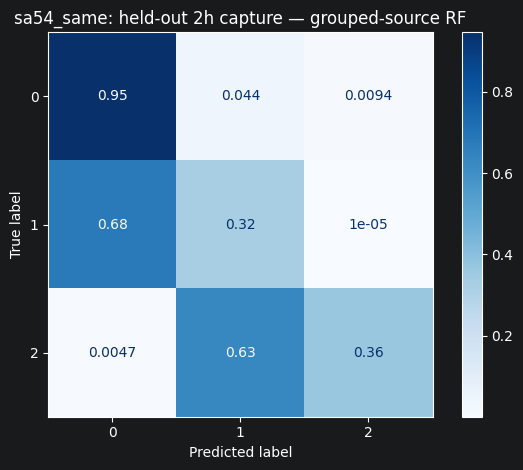

In [5]:
# Held-out 2h evaluation.  This is the metric to compare across the four experiments.
X_eval = eval_df.reindex(columns=feature_columns, fill_value=0).astype('float32')
eval_pred = model.predict(X_eval)
print(classification_report(eval_df[LABEL_COL], eval_pred, zero_division=0))
held_out_macro_f1 = f1_score(eval_df[LABEL_COL], eval_pred, average='macro')
print(f'Held-out macro-F1: {held_out_macro_f1:.4f}')
ConfusionMatrixDisplay.from_predictions(eval_df[LABEL_COL], eval_pred, normalize='true', cmap='Blues')
plt.title(f'{EXPERIMENT}: held-out 2h capture — grouped-source RF')
plt.tight_layout()
plt.show()


## Recommended execution order

Start with `MAX_*_PACKETS_PER_CLASS = 50_000`, then 100,000, then 200,000. Stop increasing it when held-out macro-F1 is effectively stable. Avoid running all four notebooks at once. For final feature importance or learning curves, make a copy of this notebook and run one selected experiment only; use `n_jobs=1` for any learning-curve computation to prevent parallel worker copies from exhausting RAM.